# パイプライン処理のモジュール分割と前後処理・デバッグ

書籍 第5章「言語資源のつくり方」（5-5-1 パイプライン処理とモジュール分割、5-5-3 前処理と後処理の設計とデバッグ）に対応する演習ノートブックです。
CPU のみ・数秒で実行でき、密結合な処理を JSON Lines (`jsonl`) 通信による疎結合な Unix フィルタパイプラインへ分割し、設定外出し・前後処理のアブレーション・中間出力差分によるデバッグ・回帰テストを体験します。

1. **ノイズ付きコーパスと正解データの準備**: HTML タグ・URL・全角半角混在・否定表現を含む評価極性データ
2. **モノリシック関数 vs JSON Lines (`jsonl`) Unix フィルタパイプライン（5-5-1）**: `subprocess` パイプによる 4 段階分割、モジュール差し替えとデータ・設定外出し
3. **前後処理のアブレーションと中間 JSON Lines によるエラー局所化（5-5-3）**: 正規化除去・トークナイズ破壊・後処理除去の定量評価とステージ別差分デバッグ
4. **回帰テスト・スキーマ検証・不変性チェックと可視化（5-5-3）**: サイレントリグレッションの検出とステージ別エラー要因の可視化

---

## 1. 準備とノイズ付き日本語コーパス・正解データの構築

Web から収集した宿泊レビューを模したノイズ付き日本語コーパス（26件：`pos` 9件、`neg` 11件、`neu` 6件）を用意します。
実務のデータと同様に、HTML タグや文字参照 (`&amp;`)、属性値や URL 中の紛らわしい英単語（`status=bad`、`error_log`、`best-deal`）、半角カタカナ（`ｺｽﾊﾟ`、`ﾎｺﾘ`）、全角英数字（`ＷｉーＦｉ`、`ＮＧ`）、否定表現（`気にならない`、`満足できない`）、重大クレーム（`故障`、`返金`）を含みます。

In [1]:
import csv
import html
import json
import re
import subprocess
import sys
import tempfile
import unicodedata
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

CORPUS = [
    # pos (9件)
    {"id": "D01", "gold": "pos", "text": "<div class='rev' data-status='bad'>ｺｽﾊﾟ最高！</div> &amp; ｵｽｽﾒです。 https://shop.example.com/item?id=1&status=bad"},
    {"id": "D02", "gold": "pos", "text": "ＷｉーＦｉが安定していてｶｲﾃｷでした！！　https://example.com/error_log"},
    {"id": "D03", "gold": "pos", "text": "<p data-err='error'>ﾌﾛﾝﾄの対応がｽﾑｰｽﾞでｵｽｽﾒの宿です。</p>"},
    {"id": "D04", "gold": "pos", "text": "部屋の清潔感が高く、静かでよく眠れました。問題ないです！"},
    {"id": "D05", "gold": "pos", "text": "大通り沿いですが二重窓のおかげで騒音は気にならないです。"},
    {"id": "D06", "gold": "pos", "text": "値段相応かと思いましたが予想以上に綺麗で満足です。"},
    {"id": "D07", "gold": "pos", "text": "朝食のﾊﾟﾝがｵｲｼｲし、またﾘﾋﾟｰﾄします。"},
    {"id": "D08", "gold": "pos", "text": "古い建物ですが清掃が行き届いていて悪くない滞在でした。"},
    {"id": "D09", "gold": "pos", "text": "<b>１００％満足</b>の宿泊体験です。ｱﾒﾆﾃｨもｼﾞｭｳｼﾞﾂしています。"},
    # neg (11件; D25, D26 は肯定語も多いが重大クレームを含む混合文)
    {"id": "D10", "gold": "neg", "text": "<p>ｼｬﾜｰが故障していてｻｲｱｸでした。</p> 返金を求めたいレベル。"},
    {"id": "D11", "gold": "neg", "text": "ＷｉーＦｉが頻繁に切れて仕事になりません。ＮＧな環境です。"},
    {"id": "D12", "gold": "neg", "text": "廊下の声が丸聞こえでうるさい。清潔とは言えない状態でした。"},
    {"id": "D13", "gold": "neg", "text": "予約内容が伝わっておらず待たされた。受付の態度も不親切です。"},
    {"id": "D14", "gold": "neg", "text": "部屋にﾎｺﾘとｶﾋﾞの臭いが残っていてﾌｶｲでした。 https://example.com/best-hotel"},
    {"id": "D15", "gold": "neg", "text": "写真よりかなり狭く、暖房も効かず寒かった。残念です。"},
    {"id": "D16", "gold": "neg", "text": "チェックアウト時の案内が雑でがっかりしました。満足できない。"},
    {"id": "D17", "gold": "neg", "text": "ｴﾚﾍﾞｰﾀｰが遅くて混雑しており、朝の移動が大変でした。"},
    {"id": "D18", "gold": "neg", "text": "料金が割高なうえに清掃が不十分でｺﾞﾐが落ちていました。"},
    {"id": "D25", "gold": "neg", "text": "フロントは丁寧で部屋も快適で満足しましたが、シャワーが故障していました。"},
    {"id": "D26", "gold": "neg", "text": "立地が良く清掃も行き届いていましたが、返金対応が必要な重大不備でした。"},
    # neu (6件)
    {"id": "D19", "gold": "neu", "text": "出張で利用しました。南口から徒歩５分です。 https://example.com/best-deal"},
    {"id": "D20", "gold": "neu", "text": "<span class='best'>自動ﾁｪｯｸｲﾝ機での手続きでした。</span> 領収書も発行可能。"},
    {"id": "D21", "gold": "neu", "text": "１階にコンビニとカフェが入っています。エレベーターは２基です。"},
    {"id": "D22", "gold": "neu", "text": "価格は普通で、設備も相応です。良い点も悪い点も特にありません。"},
    {"id": "D23", "gold": "neu", "text": "チェックインは１５時、チェックアウトは１１時のプランです。"},
    {"id": "D24", "gold": "neu", "text": "駅前のビジネスホテルです。詳細は公式ページを確認してください。 https://example.com/good_bad"},
]

df_corpus = pd.DataFrame(CORPUS)
print("件数:", len(df_corpus), "| ラベル分布:", df_corpus["gold"].value_counts().to_dict())
pd.set_option("display.max_colwidth", 80)
display(df_corpus.iloc[[0, 1, 9, 13, 18, 20]])

件数: 26 | ラベル分布: {'neg': 11, 'pos': 9, 'neu': 6}


,id,gold,text
0,D01,pos,<div class='rev' data-status='bad'>ｺｽﾊﾟ最高！</div> &amp; ｵｽｽﾒです。 https://shop....
1,D02,pos,ＷｉーＦｉが安定していてｶｲﾃｷでした！！ https://example.com/error_log
9,D10,neg,<p>ｼｬﾜｰが故障していてｻｲｱｸでした。</p> 返金を求めたいレベル。
13,D14,neg,部屋にﾎｺﾘとｶﾋﾞの臭いが残っていてﾌｶｲでした。 https://example.com/best-hotel
18,D25,neg,フロントは丁寧で部屋も快適で満足しましたが、シャワーが故障していました。
20,D19,neu,出張で利用しました。南口から徒歩５分です。 https://example.com/best-deal


---

## 2. モノリシック関数 vs JSON Lines (`jsonl`) パイプラインとモジュール差し替え（5-5-1）

書籍 5-5-1 では、ツール開発において**パイプライン処理を単機能のモジュールへ分割し、テキストベース（TSV や JSON Lines など）でデータを受け渡すこと**の重要性が述べられています。

- **モノリシック関数**: 前処理・語彙分割・スコアリング・後処理が 1 つの関数に密結合しているため、途中の状態を観察しにくく、一部のロジックだけを差し替えたり、辞書データだけを更新したりするのが困難です。
- **Unix フィルタ型 JSON Lines パイプライン**: 各ステージが `stdin` から 1 行 1 JSON レコードを読み、自分の担当フィールドを追記して `stdout` へ流します。辞書重みや閾値も外部ファイル (`weights.tsv`, `terms.json`, `postprocess.json`) へ外出しできるため、他ステージを一切変更せずにモジュール差し替えや設定調整を行えます。

In [2]:
# (比較対象) 密結合なモノリシック関数
def monolithic_analyze(raw_text):
    t = unicodedata.normalize("NFKC", re.sub(r"<[^>]+>|https?://\S+", " ", html.unescape(raw_text)))
    pos_kw = {"快適", "満足", "清潔", "親切", "丁寧", "綺麗", "静か", "美味しい"}
    neg_kw = {"故障", "最悪", "返金", "うるさい", "不親切", "残念", "がっかり"}
    score = sum(1 for w in pos_kw if w in t) - sum(1 for w in neg_kw if w in t)
    return "pos" if score > 0 else ("neg" if score < 0 else "neu")

print("モノリシック関数の正解率:", round(accuracy_score(
    [r["gold"] for r in CORPUS],
    [monolithic_analyze(r["text"]) for r in CORPUS]
), 3))

# 一時ディレクトリ内に 4 ステージの独立フィルタスクリプトと外部設定ファイルを構築
tmpdir = tempfile.TemporaryDirectory()
wdir = Path(tmpdir.name)

WEIGHTS = [
    ("コスパ最高", 2.0), ("オススメ", 1.5), ("カイテキ", 1.5), ("安定", 1.2), ("快適", 1.5),
    ("スムーズ", 1.3), ("丁寧", 1.5), ("親切", 1.5), ("安心", 1.2), ("清潔感", 1.5), ("清潔", 1.4),
    ("静か", 1.2), ("問題ない", 1.2), ("気にならない", 1.8), ("綺麗", 1.4), ("満足", 1.5),
    ("オイシイ", 1.4), ("美味しい", 1.4), ("リピート", 1.3), ("行き届いて", 1.4), ("悪くない", 1.1),
    ("ジュウジツ", 1.2), ("充実", 1.2), ("良い", 1.0), ("good", 1.5), ("best", 1.5),
    ("故障", -2.0), ("サイアク", -2.0), ("最悪", -2.0), ("返金", -2.2), ("切れて", -1.4),
    ("NG", -1.6), ("丸聞こえ", -1.6), ("うるさい", -1.5), ("待たされた", -1.5), ("不親切", -1.6),
    ("ホコリ", -1.5), ("カビ", -1.6), ("臭い", -1.4), ("フカイ", -1.6), ("不快", -1.6),
    ("狭く", -1.3), ("寒かった", -1.4), ("残念", -1.4), ("雑", -1.3), ("がっかり", -1.5),
    ("遅くて", -1.3), ("混雑", -1.2), ("大変", -1.1), ("割高", -1.4), ("不十分", -1.5),
    ("ゴミ", -1.5), ("悪い", -1.0), ("問題", -1.1), ("騒音", -1.3), ("bad", -2.0), ("error", -2.0),
]

critical_terms = {"故障", "返金", "最悪", "サイアク"}
tsv_lines = ["term\tweight\tcritical"]
for term, wt in WEIGHTS:
    tsv_lines.append(f"{term}\t{wt}\t{1 if term in critical_terms else 0}")
(wdir / "weights.tsv").write_text("\n".join(tsv_lines) + "\n", encoding="utf-8")

terms_sorted = sorted(
    [t for t, _ in WEIGHTS] + ["Wi-Fi", "チェックイン", "チェックアウト", "エレベーター", "アメニティ"],
    key=len,
    reverse=True,
)
(wdir / "terms.json").write_text(json.dumps(terms_sorted, ensure_ascii=False, indent=2), encoding="utf-8")
(wdir / "postprocess.json").write_text(
    json.dumps({"neutral_margin": 0.4, "critical_override": True, "allowed_labels": ["pos", "neg", "neu"]}, indent=2),
    encoding="utf-8",
)

# Stage 1: 正規化フィルタ
(wdir / "01_normalize.py").write_text(r'''import argparse, html, json, re, sys, unicodedata

def normalize_text(text):
    text = html.unescape(text)
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"https?://\S+", " ", text)
    text = unicodedata.normalize("NFKC", text)
    text = re.sub(r"([A-Za-z0-9])[ー−‐]([A-Za-z0-9])", r"\1-\2", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

parser = argparse.ArgumentParser()
parser.add_argument("--skip", action="store_true")
args = parser.parse_args()

for line in sys.stdin:
    if not line.strip():
        continue
    rec = json.loads(line)
    rec["norm_text"] = rec["text"] if args.skip else normalize_text(rec["text"])
    sys.stdout.write(json.dumps(rec, ensure_ascii=False) + "\n")
''', encoding="utf-8")

# Stage 2: トークナイズ + 否定結合フィルタ
(wdir / "02_tokenize.py").write_text(r'''import argparse, json, re, sys
from pathlib import Path

NEG_SUFFIXES = ("とは言えない", "できない", "ではない", "ない", "ません", "ず")

def tokenize_smart(text, vocab):
    vocab_pat = "|".join(re.escape(v) for v in vocab)
    token_re = re.compile(vocab_pat + r"|[A-Za-z0-9-]+|[ァ-ヶー]+|[一-龥]|[ぁ-ん]|\S")
    tokens = []
    vocab_set = set(vocab)
    for m in token_re.finditer(text):
        tok = m.group(0)
        rest = text[m.end():m.end() + 8]
        if tok in vocab_set and tok not in {"問題ない", "気にならない", "悪くない"} and any(rest.startswith(neg) for neg in NEG_SUFFIXES):
            tokens.append(f"NOT_{tok}")
        else:
            tokens.append(tok)
    return tokens

parser = argparse.ArgumentParser()
parser.add_argument("--terms", required=True)
parser.add_argument("--broken", action="store_true")
args = parser.parse_args()
vocab = json.loads(Path(args.terms).read_text(encoding="utf-8"))

for line in sys.stdin:
    if not line.strip():
        continue
    rec = json.loads(line)
    txt = rec["norm_text"]
    if args.broken:
        rec["tokens"] = [t for t in re.split(r"[\s、。・！!？?]+", txt) if t]
    else:
        rec["tokens"] = tokenize_smart(txt, vocab)
    sys.stdout.write(json.dumps(rec, ensure_ascii=False) + "\n")
''', encoding="utf-8")

# Stage 3a: 単純ルールスコアラー（差し替え前ベースライン）
(wdir / "03_score_rule.py").write_text(r'''import json, sys

POS_SIMPLE = {"良い", "快適", "満足", "親切", "丁寧", "綺麗", "静か", "美味しい"}
NEG_SIMPLE = {"悪い", "不満", "残念", "うるさい", "狭く", "遅くて", "不快", "最悪"}

for line in sys.stdin:
    if not line.strip():
        continue
    rec = json.loads(line)
    score, hits = 0.0, []
    for tok in rec["tokens"]:
        if tok in POS_SIMPLE:
            score += 1.0
            hits.append([tok, 1.0])
        elif tok in NEG_SIMPLE:
            score -= 1.0
            hits.append([tok, -1.0])
    rec["score"] = round(score, 4)
    rec["hits"] = hits
    rec["critical_hits"] = []
    rec["raw_label"] = "pos" if score > 0 else ("neg" if score < 0 else "neu")
    sys.stdout.write(json.dumps(rec, ensure_ascii=False) + "\n")
''', encoding="utf-8")

# Stage 3b: 外出し TSV 重み辞書スコアラー（差し替え後）
(wdir / "03_score_lexicon.py").write_text(r'''import argparse, csv, json, sys

parser = argparse.ArgumentParser()
parser.add_argument("--lexicon", required=True)
args = parser.parse_args()

weights, critical = {}, set()
with open(args.lexicon, encoding="utf-8") as f:
    for row in csv.DictReader(f, delimiter="\t"):
        weights[row["term"]] = float(row["weight"])
        if int(row["critical"]) == 1:
            critical.add(row["term"])

for line in sys.stdin:
    if not line.strip():
        continue
    rec = json.loads(line)
    score, hits, crit = 0.0, [], []
    for tok in rec["tokens"]:
        if tok.startswith("NOT_"):
            base = tok[4:]
            if base in weights:
                w = -weights[base]
                score += w
                hits.append([tok, w])
        elif tok in weights:
            w = weights[tok]
            score += w
            hits.append([tok, w])
            if tok in critical:
                crit.append(tok)
    rec["score"] = round(score, 4)
    rec["hits"] = hits
    rec["critical_hits"] = crit
    rec["raw_label"] = "pos" if score > 0 else ("neg" if score < 0 else "neu")
    sys.stdout.write(json.dumps(rec, ensure_ascii=False) + "\n")
''', encoding="utf-8")

# Stage 4: 後処理・重大クレーム補正・スキーマ確定フィルタ
(wdir / "04_postprocess.py").write_text(r'''import argparse, json, sys
from pathlib import Path

parser = argparse.ArgumentParser()
parser.add_argument("--config", required=True)
parser.add_argument("--skip", action="store_true")
args = parser.parse_args()
cfg = json.loads(Path(args.config).read_text(encoding="utf-8"))

for line in sys.stdin:
    if not line.strip():
        continue
    rec = json.loads(line)
    if args.skip:
        rec["pred_label"] = "pos" if rec["score"] >= 0 else "neg"
        rec["post_reason"] = "no_postprocess_binary_fallback"
    else:
        margin = cfg["neutral_margin"]
        if cfg["critical_override"] and rec.get("critical_hits"):
            rec["pred_label"] = "neg"
            rec["post_reason"] = f"critical_override:{','.join(rec['critical_hits'])}"
        elif abs(rec["score"]) < margin:
            rec["pred_label"] = "neu"
            rec["post_reason"] = f"within_neutral_margin({rec['score']})"
        else:
            rec["pred_label"] = "pos" if rec["score"] > 0 else "neg"
            rec["post_reason"] = "score_threshold"
    sys.stdout.write(json.dumps(rec, ensure_ascii=False) + "\n")
''', encoding="utf-8")

print("生成したパイプラインファイル一覧:", sorted(p.name for p in wdir.iterdir()))

モノリシック関数の正解率: 0.462
生成したパイプラインファイル一覧: ['01_normalize.py', '02_tokenize.py', '03_score_lexicon.py', '03_score_rule.py', '04_postprocess.py', 'postprocess.json', 'terms.json', 'weights.tsv']


In [3]:
def build_stage_cmds(skip_norm=False, broken_tok=False, use_simple_scorer=False, skip_post=False):
    c1 = [sys.executable, str(wdir / "01_normalize.py")] + (["--skip"] if skip_norm else [])
    c2 = [sys.executable, str(wdir / "02_tokenize.py"), "--terms", str(wdir / "terms.json")] + (["--broken"] if broken_tok else [])
    c3 = (
        [sys.executable, str(wdir / "03_score_rule.py")]
        if use_simple_scorer
        else [sys.executable, str(wdir / "03_score_lexicon.py"), "--lexicon", str(wdir / "weights.tsv")]
    )
    c4 = [sys.executable, str(wdir / "04_postprocess.py"), "--config", str(wdir / "postprocess.json")] + (["--skip"] if skip_post else [])
    return [("stage1_norm", c1), ("stage2_tok", c2), ("stage3_score", c3), ("stage4_post", c4)]

def run_unix_pipe(records, **kwargs):
    '''Unix パイプライン (p1 | p2 | p3 | p4) として Popen で連結実行する'''
    in_jsonl = "\n".join(json.dumps(r, ensure_ascii=False) for r in records) + "\n"
    cmds = [cmd for _, cmd in build_stage_cmds(**kwargs)]
    p1 = subprocess.Popen(cmds[0], stdin=subprocess.PIPE, stdout=subprocess.PIPE, text=True)
    p2 = subprocess.Popen(cmds[1], stdin=p1.stdout, stdout=subprocess.PIPE, text=True)
    p1.stdout.close()
    p3 = subprocess.Popen(cmds[2], stdin=p2.stdout, stdout=subprocess.PIPE, text=True)
    p2.stdout.close()
    p4 = subprocess.Popen(cmds[3], stdin=p3.stdout, stdout=subprocess.PIPE, text=True)
    p3.stdout.close()

    p1.stdin.write(in_jsonl)
    p1.stdin.close()
    out_text, _ = p4.communicate()
    for p in (p1, p2, p3, p4):
        ret = p.wait()
        assert ret == 0, f"ステージ終了コード異常: {ret}"
    return [json.loads(line) for line in out_text.splitlines() if line.strip()]

def run_pipeline_with_stages(records, **kwargs):
    '''デバッグ用に各ステージの中間 JSON Lines を保持しながら実行する'''
    cur = "\n".join(json.dumps(r, ensure_ascii=False) for r in records) + "\n"
    snapshots = {}
    for stage_name, cmd in build_stage_cmds(**kwargs):
        proc = subprocess.run(cmd, input=cur, text=True, capture_output=True, check=True)
        cur = proc.stdout
        snapshots[stage_name] = [json.loads(line) for line in cur.splitlines() if line.strip()]
    return snapshots["stage4_post"], snapshots

# モジュール差し替え比較: Stage 3 のみ 03_score_rule.py -> 03_score_lexicon.py に差し替え
out_simple = run_unix_pipe(CORPUS, use_simple_scorer=True)
out_lex = run_unix_pipe(CORPUS, use_simple_scorer=False)

for label, recs in [("差し替え前 (03_score_rule.py)", out_simple), ("差し替え後 (03_score_lexicon.py + weights.tsv)", out_lex)]:
    y_t = [r["gold"] for r in recs]
    y_p = [r["pred_label"] for r in recs]
    print(f"{label:48s}: Accuracy={accuracy_score(y_t, y_p):.3f}, Macro-F1={precision_recall_fscore_support(y_t, y_p, average='macro', zero_division=0)[2]:.3f}")

print("\n--- パイプライン出力サンプル（JSON Lines レコード例: D01, D25） ---")
for sample in [r for r in out_lex if r["id"] in {"D01", "D25"}]:
    print(json.dumps({k: sample[k] for k in ["id", "gold", "norm_text", "score", "hits", "critical_hits", "raw_label", "pred_label", "post_reason"]}, ensure_ascii=False))

差し替え前 (03_score_rule.py)                        : Accuracy=0.462, Macro-F1=0.457
差し替え後 (03_score_lexicon.py + weights.tsv)       : Accuracy=1.000, Macro-F1=1.000

--- パイプライン出力サンプル（JSON Lines レコード例: D01, D25） ---
{"id": "D01", "gold": "pos", "norm_text": "コスパ最高! & オススメです。", "score": 3.5, "hits": [["コスパ最高", 2.0], ["オススメ", 1.5]], "critical_hits": [], "raw_label": "pos", "pred_label": "pos", "post_reason": "score_threshold"}
{"id": "D25", "gold": "neg", "norm_text": "フロントは丁寧で部屋も快適で満足しましたが、シャワーが故障していました。", "score": 2.5, "hits": [["丁寧", 1.5], ["快適", 1.5], ["満足", 1.5], ["故障", -2.0]], "critical_hits": ["故障"], "raw_label": "pos", "pred_label": "neg", "post_reason": "critical_override:故障"}


---

## 3. 前処理・後処理のアブレーションと中間 JSON Lines によるエラー局所化（5-5-3）

書籍 5-5-3 では、前処理や後処理の不備が下流モデルの性能を大きく左右すること、およびパイプライン化していれば**各ステージの中間出力 (JSON Lines) を比較して「どの処理段階が原因で誤りが生じたか」を切り分けられる**ことが解説されています。

ここでは、以下の 5 構成でアブレーション評価を行います。
1. **Full Pipeline**: 正規化 ＋ 語彙・否定認識トークナイザ ＋ 外出し TSV スコアラー ＋ 後処理
2. **Swapped Module**: Stage 3 のみ単純ルールスコアラーへ差し替え
3. **No Normalization**: Stage 1 をスキップ（HTML・URL・全角半角が残存）
4. **Broken Tokenizer**: Stage 2 を素朴な空白・句読点分割へ劣化
5. **No Postprocessing**: Stage 4 をスキップ（中立マージン判定・重大クレーム上書きなし）

In [4]:
configs = [
    ("Full Pipeline (External TSV+JSON)", dict()),
    ("Swapped Module (Simple Rule)", dict(use_simple_scorer=True)),
    ("Ablation: No Normalization", dict(skip_norm=True)),
    ("Ablation: Broken Tokenizer", dict(broken_tok=True)),
    ("Ablation: No Postprocessing", dict(skip_post=True)),
]

ablation_rows = []
stage_logs = {}
for name, kw in configs:
    final_recs, snaps = run_pipeline_with_stages(CORPUS, **kw)
    stage_logs[name] = snaps
    y_true = [r["gold"] for r in final_recs]
    y_pred = [r["pred_label"] for r in final_recs]
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    errs = [x["id"] for x in final_recs if x["gold"] != x["pred_label"]]
    ablation_rows.append({
        "構成": name,
        "Accuracy": round(accuracy_score(y_true, y_pred), 3),
        "Macro-P": round(p, 3),
        "Macro-R": round(r, 3),
        "Macro-F1": round(f1, 3),
        "誤り件数": len(errs),
        "誤りID": ", ".join(errs) if errs else "(なし)",
    })

ablation_df = pd.DataFrame(ablation_rows)
display(ablation_df)

# 中間 JSON Lines の差分によるエラー原因ステージの自動特定
def localize_earliest_divergence(gold_snaps, broken_snaps):
    by_id_gold = {s: {r["id"]: r for r in recs} for s, recs in gold_snaps.items()}
    by_id_brok = {s: {r["id"]: r for r in recs} for s, recs in broken_snaps.items()}
    stage_checks = [
        ("stage1_norm", "norm_text", "Stage 1: Normalize"),
        ("stage2_tok", "tokens", "Stage 2: Tokenize"),
        ("stage3_score", "score", "Stage 3: Score"),
        ("stage4_post", "pred_label", "Stage 4: Postprocess"),
    ]
    rows = []
    for rec in broken_snaps["stage4_post"]:
        if rec["pred_label"] == rec["gold"]:
            continue
        rid = rec["id"]
        found_stage = "Unknown"
        diff_detail = ""
        for st_key, field, st_label in stage_checks:
            g_val = by_id_gold[st_key][rid][field]
            b_val = by_id_brok[st_key][rid][field]
            if g_val != b_val:
                found_stage = st_label
                diff_detail = f"{field}: {repr(g_val)[:38]} != {repr(b_val)[:38]}"
                break
        rows.append({"ID": rid, "正解": rec["gold"], "誤予測": rec["pred_label"], "最上流の原因ステージ": found_stage, "中間JSON差分": diff_detail})
    return pd.DataFrame(rows)

print("--- 中間 JSON Lines 差分によるエラー局所化（代表例） ---")
for abl_name in ["Ablation: No Normalization", "Ablation: Broken Tokenizer", "Ablation: No Postprocessing"]:
    print(f"\n[{abl_name}]")
    display(localize_earliest_divergence(stage_logs["Full Pipeline (External TSV+JSON)"], stage_logs[abl_name]).head(4))

,構成,Accuracy,Macro-P,Macro-R,Macro-F1,誤り件数,誤りID
0,Full Pipeline (External TSV+JSON),1.000,1.000,1.000,1.000,0,(なし)
1,Swapped Module (Simple Rule),0.462,0.689,0.535,0.457,14,"D01, D02, D03, D05, D07, D08, D10, D11, D13, D14, D16, D18, D25, D26"
2,Ablation: No Normalization,0.692,0.676,0.655,0.657,8,"D01, D02, D03, D07, D14, D19, D20, D24"
3,Ablation: Broken Tokenizer,0.269,0.413,0.370,0.196,19,"D02, D03, D04, D05, D06, D07, D08, D09, D10, D11, D12, D13, D14, D15, D16, D..."
4,Ablation: No Postprocessing,0.731,0.521,0.636,0.557,7,"D25, D19, D20, D21, D22, D23, D24"


--- 中間 JSON Lines 差分によるエラー局所化（代表例） ---

[Ablation: No Normalization]


,ID,正解,誤予測,最上流の原因ステージ,中間JSON差分
0,D01,pos,neg,Stage 1: Normalize,"norm_text: 'コスパ最高! & オススメです。' != ""<div class='rev' data-status='bad'>ｺｽ"
1,D02,pos,neg,Stage 1: Normalize,norm_text: 'Wi-Fiが安定していてカイテキでした!!' != 'ＷｉーＦｉが安定していてｶｲﾃｷでした！！\u3000https://ex
2,D03,pos,neg,Stage 1: Normalize,"norm_text: 'フロントの対応がスムーズでオススメの宿です。' != ""<p data-err='error'>ﾌﾛﾝﾄの対応がｽﾑｰｽﾞでｵｽｽ"
3,D07,pos,neu,Stage 1: Normalize,norm_text: '朝食のパンがオイシイし、またリピートします。' != '朝食のﾊﾟﾝがｵｲｼｲし、またﾘﾋﾟｰﾄします。'



[Ablation: Broken Tokenizer]


,ID,正解,誤予測,最上流の原因ステージ,中間JSON差分
0,D02,pos,neu,Stage 2: Tokenize,"tokens: ['Wi-Fi', 'が', '安定', 'し', 'て', 'い', 'て != ['Wi-Fiが安定していてカイテキでした']"
1,D03,pos,neu,Stage 2: Tokenize,"tokens: ['フロント', 'の', '対', '応', 'が', 'スムーズ', ' != ['フロントの対応がスムーズでオススメの宿です']"
2,D04,pos,neu,Stage 2: Tokenize,"tokens: ['部', '屋', 'の', '清潔感', 'が', '高', 'く', != ['部屋の清潔感が高く', '静かでよく眠れました'..."
3,D05,pos,neu,Stage 2: Tokenize,"tokens: ['大', '通', 'り', '沿', 'い', 'で', 'す', 'が != ['大通り沿いですが二重窓のおかげで騒音は気にならな..."



[Ablation: No Postprocessing]


,ID,正解,誤予測,最上流の原因ステージ,中間JSON差分
0,D25,neg,pos,Stage 4: Postprocess,pred_label: 'neg' != 'pos'
1,D19,neu,pos,Stage 4: Postprocess,pred_label: 'neu' != 'pos'
2,D20,neu,pos,Stage 4: Postprocess,pred_label: 'neu' != 'pos'
3,D21,neu,pos,Stage 4: Postprocess,pred_label: 'neu' != 'pos'


---

## 4. 回帰テスト・スキーマ検証・不変性チェックとまとめ可視化（5-5-3）

書籍 5-5-3 では、前処理や辞書を更新したときに**別の入力や既存テストケースが壊れていないか（サイレントリグレッション）を検出するためのテスト**の重要性が強調されています。

1. **スキーマ検証**: 各レコードが必須キーと許容ラベル集合 (`pos` / `neg` / `neu`) を満たすか検査
2. **冪等性・決定性テスト**: 正規化を 2 回適用しても出力が変わらないこと（冪等性）、同一入力で常に同一 JSON Lines を返すこと（決定性）を検証
3. **ゴールデンセット回帰テスト**: 誤りやすい境界ケース（URL 混入、全角半角、否定反転、重大クレーム上書き）を含むテストを実行し、外部設定を誤って壊した際に即座に検知できることを確認

回帰テスト全項目に合格しました（Macro-F1 = 1.000）


設定変更によるリグレッションを自動検出: D25 (重大クレーム上書き '故障') 失敗


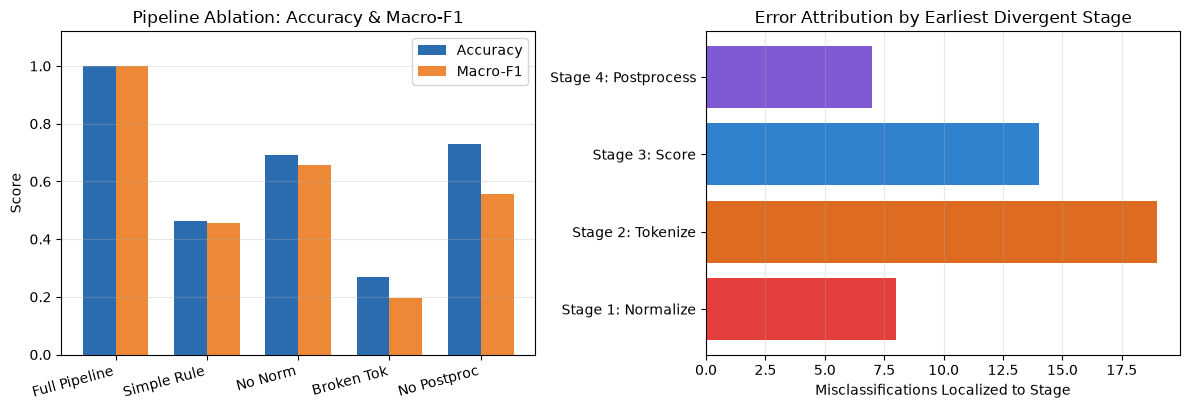

In [5]:
REQUIRED_KEYS = {"id", "gold", "text", "norm_text", "tokens", "score", "hits", "critical_hits", "raw_label", "pred_label", "post_reason"}

def validate_schema(records):
    for rec in records:
        missing = REQUIRED_KEYS - set(rec.keys())
        assert not missing, f"{rec.get('id')}: 欠損キー {missing}"
        assert isinstance(rec["tokens"], list), f"{rec['id']}: tokens は list である必要があります"
        assert isinstance(rec["score"], (int, float)), f"{rec['id']}: score が数値ではありません"
        assert rec["pred_label"] in {"pos", "neg", "neu"}, f"{rec['id']}: 不正ラベル {rec['pred_label']}"

def run_regression_suite(records, min_f1=0.95):
    run1 = run_unix_pipe(records)
    run2 = run_unix_pipe(records)
    validate_schema(run1)
    # 1) 決定性チェック
    assert run1 == run2, "パイプライン出力が決定的ではありません"
    # 2) 正規化の冪等性チェック: norm_text を再入力しても norm_text と pred_label が不変
    re_input = [{"id": r["id"], "gold": r["gold"], "text": r["norm_text"]} for r in run1]
    run_idem = run_unix_pipe(re_input)
    for a, b in zip(run1, run_idem):
        assert a["norm_text"] == b["norm_text"], f"{a['id']}: 正規化が冪等ではありません"
        assert a["pred_label"] == b["pred_label"], f"{a['id']}: 再入力で予測が変化しました"
    # 3) ゴールデンセット性能と重要エッジケースのアサーション
    y_t = [r["gold"] for r in run1]
    y_p = [r["pred_label"] for r in run1]
    f1 = precision_recall_fscore_support(y_t, y_p, average="macro", zero_division=0)[2]
    assert f1 >= min_f1, f"Macro-F1 低下を検出: {f1:.3f} < {min_f1:.3f}"
    by_id = {r["id"]: r for r in run1}
    assert by_id["D01"]["pred_label"] == "pos", "D01 (HTML属性/URLノイズ+半角カナ) 失敗"
    assert by_id["D05"]["pred_label"] == "pos", "D05 (否定表現 '気にならない') 失敗"
    assert by_id["D19"]["pred_label"] == "neu", "D19 (URL内 'best-deal' 汚染防止) 失敗"
    assert by_id["D25"]["pred_label"] == "neg", "D25 (重大クレーム上書き '故障') 失敗"
    return f1

f1_pass = run_regression_suite(CORPUS)
print(f"回帰テスト全項目に合格しました（Macro-F1 = {f1_pass:.3f}）")

# サイレントリグレッションの再現テスト: postprocess.json の critical_override を誤って False に変更した場合
orig_cfg = (wdir / "postprocess.json").read_text(encoding="utf-8")
try:
    bad_cfg = json.loads(orig_cfg)
    bad_cfg["critical_override"] = False
    (wdir / "postprocess.json").write_text(json.dumps(bad_cfg), encoding="utf-8")
    try:
        run_regression_suite(CORPUS)
    except AssertionError as e:
        print("設定変更によるリグレッションを自動検出:", e)
finally:
    (wdir / "postprocess.json").write_text(orig_cfg, encoding="utf-8")

assert run_regression_suite(CORPUS) == f1_pass

# 英語ラベルによるまとめ可視化
short_names = ["Full Pipeline", "Simple Rule", "No Norm", "Broken Tok", "No Postproc"]
accs = ablation_df["Accuracy"].tolist()
f1s = ablation_df["Macro-F1"].tolist()

# ステージ別の最上流エラー発生件数（アブレーション4種合算）
stage_counts = {"Stage 1: Normalize": 0, "Stage 2: Tokenize": 0, "Stage 3: Score": 0, "Stage 4: Postprocess": 0}
for abl_name in ["Swapped Module (Simple Rule)", "Ablation: No Normalization", "Ablation: Broken Tokenizer", "Ablation: No Postprocessing"]:
    df_loc = localize_earliest_divergence(stage_logs["Full Pipeline (External TSV+JSON)"], stage_logs[abl_name])
    for st in df_loc["最上流の原因ステージ"]:
        if st in stage_counts:
            stage_counts[st] += 1

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
x = np.arange(len(short_names))
width = 0.36
axes[0].bar(x - width / 2, accs, width, label="Accuracy", color="#2b6cb0")
axes[0].bar(x + width / 2, f1s, width, label="Macro-F1", color="#ed8936")
axes[0].set_xticks(x)
axes[0].set_xticklabels(short_names, rotation=15, ha="right")
axes[0].set_ylim(0.0, 1.12)
axes[0].set_ylabel("Score")
axes[0].set_title("Pipeline Ablation: Accuracy & Macro-F1")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)

st_labels = list(stage_counts.keys())
st_vals = list(stage_counts.values())
axes[1].barh(st_labels, st_vals, color=["#e53e3e", "#dd6b20", "#3182ce", "#805ad5"])
axes[1].set_xlabel("Misclassifications Localized to Stage")
axes[1].set_title("Error Attribution by Earliest Divergent Stage")
axes[1].grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

tmpdir.cleanup()